# 10 – Bilddaten verstehen und ein erstes neuronales Netz trainieren

**Lernsituation „KI-Sichtprüfstation“ · Doppelstunden 1 – 4**

In diesem Notebook baust du die komplette Kette einmal selbst auf – von den Kamerabildern bis zur ersten Vorhersage eines neuronalen Netzes. Viele Teile sind vorgegeben, an den markierten Stellen schreibst du den Code selbst.

### Lernziele
Du kannst …
- den Unterschied zwischen klassischer Programmierung und maschinellem Lernen erklären,
- erklären, wie ein Bild als Zahlenmatrix gespeichert ist, und Bilder mit OpenCV laden und vorbereiten,
- einen Datensatz in Trainings-, Validierungs- und Testdaten aufteilen und die Aufteilung begründen,
- den Aufbau eines künstlichen Neurons und eines vollvernetzten Netzes beschreiben,
- ein kleines Netz mit Keras aufbauen, trainieren und auf einem Einzelbild anwenden.

### Ablauf
| Teil | Doppelstunde | Inhalt |
|---|:--:|---|
| A | 1 | Szenario, Grundbegriffe, eigenen Datensatz aufnehmen (`00_Datensatz_aufnehmen.py`) |
| B | 2 | Bilder als Zahlen, Datensatz laden, vorbereiten und aufteilen · 🧪 Teilzielkontrolle 1 |
| C | 3 | Neuron, Softmax, One-Hot, erstes Modell bauen |
| D | 4 | Gradientenabstieg, Training, Bewertung, Einzelbild-Vorhersage |

| Symbol | Bedeutung |
|:--:|---|
| 📖 | Grundlagen lesen / interaktiv erkunden |
| ✏️ | Aufgabe: Code **selbst schreiben** (Zellen mit `# TODO`) |
| 🔍 | Experiment / Beobachtung – Ergebnisse notieren |
| 🧪 | Teilzielkontrolle |
| 🏭 | Bezug zur industriellen Fertigung |
| 🍓 | Hinweis für den Raspberry Pi |

---
## Teil A – Worum geht es? (Doppelstunde 1)

### 🏭 Das Szenario
Ein mittelständischer Zulieferer möchte am Ende einer Montagelinie eine **kostengünstige KI-Sichtprüfstation** einführen. Eine Kamera fotografiert jedes Teil, ein Raspberry Pi entscheidet, zu welcher Klasse es gehört, und steuert eine Ampel bzw. eine Weiche.

Bevor echte Bauteile geprüft werden, entwickelt euer Team einen **Prototyp mit vier Symbolen**: Kreuz, Kreis, Dreieck und Quadrat. Sie stehen stellvertretend für Teiletypen, Fehlerarten oder Prüfmarken. Am Ende der Lernsituation übertragt ihr die Pipeline auf eigene, industrienahe Klassen.

![Prüfstation](material/bilder/pruefstation.svg)

### 📖 Klassische Programmierung oder maschinelles Lernen?

| | Klassische Programmierung | Maschinelles Lernen (ML) |
|---|---|---|
| Eingabe | Daten **und Regeln** | Daten **und richtige Antworten (Labels)** |
| Ergebnis | Antworten | **Regeln** (ein trainiertes Modell) |
| Beispiel | „Wenn 4 gerade Kanten und 4 rechte Winkel → Quadrat“ | 400 Bilder von Quadraten + 400 Bilder von Kreisen … → das Netz findet selbst heraus, woran man sie unterscheidet |
| Problem | Schatten, schiefe Linien, Handzeichnungen machen Regeln sehr kompliziert | braucht gute und genügend Daten |

**Künstliche Intelligenz (KI)** ist der Oberbegriff. **Maschinelles Lernen** ist der Teil der KI, der aus Beispielen lernt. **Deep Learning** nutzt dafür tiefe neuronale Netze – genau das machen wir.

Wir nutzen **überwachtes Lernen**: Zu jedem Trainingsbild ist bekannt, welche Klasse es zeigt.

![Pipeline](material/bilder/pipeline.svg)

### ✏️ Aufgabe A1 – Eigenen Datensatz aufnehmen

Das Skript `00_Datensatz_aufnehmen.py` speichert jedes Kamerabild direkt im Ordner seiner Klasse:

```
dataset_neu/
  klassen.txt      ← 0;Kreuz  1;Kreis  2;Dreieck  3;Quadrat
  0/  1/  2/  3/   ← Bilder der jeweiligen Klasse
```

**Start im Terminal** (im Ordner `datasets/symbols`, virtuelle Umgebung aktiv):

```bash
python3 00_Datensatz_aufnehmen.py --datensatz dataset_gruppe1
# eigene Klassen, z. B. später für Bauteile:
python3 00_Datensatz_aufnehmen.py --datensatz teile --klassen Schraube Mutter Scheibe Leer
```

Tasten im Kamerafenster: **0–9** speichert sofort in der Klasse, **s** startet eine Serienaufnahme, **z** macht die letzte Aufnahme rückgängig, **ESC** beendet.

**Checkliste für gute Daten** – besprecht im Team, bevor ihr loslegt:
- [ ] Beleuchtung wie später im Betrieb (gleiche Lampe, kein wechselndes Tageslicht)
- [ ] verschiedene Lagen, Drehungen, Größen und Strichstärken je Symbol
- [ ] etwa **gleich viele Bilder je Klasse** (mindestens 50, besser 150+)
- [ ] auch „schwierige“ Bilder: schräg, am Rand, leicht unscharf
- [ ] jede Person im Team zeichnet Symbole (unterschiedliche Handschriften)

🏭 *In der Fertigung entspricht das der Frage: Unter welchen Bedingungen soll die Station später zuverlässig funktionieren – und sind genau diese Bedingungen in den Trainingsdaten enthalten?*

In [1]:
# =============================================================================
# Vorbereitung: Hilfsmodul finden (klappt im Hauptordner und in loesungen/)
# =============================================================================
import sys
from pathlib import Path

ORDNER = Path.cwd() if (Path.cwd() / "ki_hilfen.py").exists() else Path.cwd().parent
sys.path.insert(0, str(ORDNER))

import numpy as np
import cv2
import matplotlib.pyplot as plt
import ki_hilfen as kh

kh.setze_seed(42, tensorflow=False)
print("Arbeitsordner:", ORDNER)

Arbeitsordner: /home/pi/ml_project/datasets/Lernsituation_KI-Sichtpruefstation/symbols


Wir beginnen mit dem kleinen Datensatz `dataset1` (176 Bilder) – damit laufen alle Zellen auch auf dem Raspberry Pi schnell. Ihr könnt jederzeit euren eigenen Datensatz oder den großen Datensatz `dataset` (1735 Bilder) eintragen.

Klassen: ['0', '1', '2', '3']
Bilder je Klasse: {'0': 44, '1': 45, '2': 44, '3': 43}


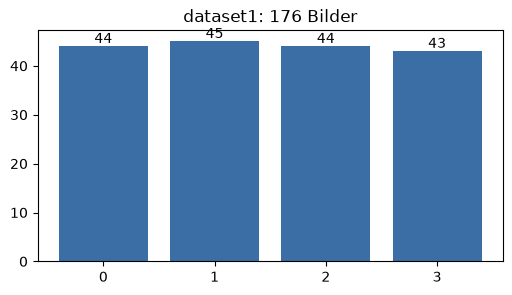

In [2]:
DATENSATZ = ORDNER / "dataset1"        # oder: "dataset", "dataset_gruppe1", ...

klassen = kh.lese_klassen(DATENSATZ)
anzahl = kh.zaehle_bilder(DATENSATZ)
print("Klassen:", klassen)
print("Bilder je Klasse:", anzahl)

plt.figure(figsize=(6, 3))
balken = plt.bar(anzahl.keys(), anzahl.values(), color="#3a6ea5")
plt.bar_label(balken)
plt.title(f"{DATENSATZ.name}: {sum(anzahl.values())} Bilder")
plt.show()

---
## Teil B – Ein Bild ist eine Zahlenmatrix (Doppelstunde 2)

### 📖 Interaktiv: Was „sieht“ das Netz?
Führe die Zelle aus und bearbeite den Arbeitsauftrag auf der Seite.

In [3]:
kh.zeige_html("01_bild_als_zahlen.html", hoehe=1150)

### 📖 Ein Kamerabild mit OpenCV laden
`cv2.imread()` liefert ein NumPy-Array mit der Form **(Höhe, Breite, Kanäle)** und dem Datentyp `uint8` (ganze Zahlen 0 … 255). **Achtung:** OpenCV speichert Farbbilder in der Reihenfolge **B, G, R** – Matplotlib erwartet **R, G, B**.

Datei:      10.png
Form:       (480, 640, 3)  → (Höhe, Breite, Kanäle)
Datentyp:   uint8
Wertebereich: 0 bis 240
Pixel oben links (B, G, R): [211 216 208]


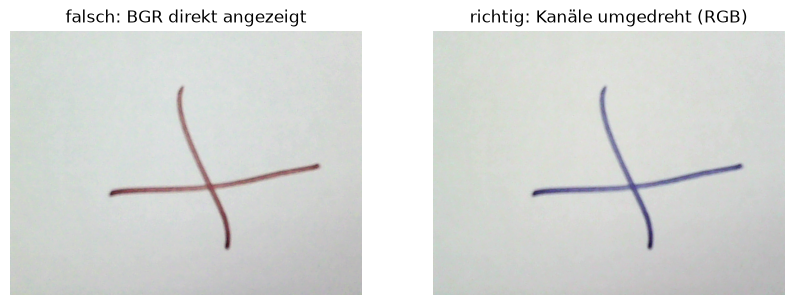

In [4]:
beispiel = kh.bilddateien(DATENSATZ / "0")[0]          # erstes Bild der Klasse 0
bild = cv2.imread(str(beispiel))

print("Datei:     ", beispiel.name)
print("Form:      ", bild.shape, " → (Höhe, Breite, Kanäle)")
print("Datentyp:  ", bild.dtype)
print("Wertebereich:", bild.min(), "bis", bild.max())
print("Pixel oben links (B, G, R):", bild[0, 0])

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(bild);                 ax[0].set_title("falsch: BGR direkt angezeigt")
ax[1].imshow(bild[..., ::-1]);      ax[1].set_title("richtig: Kanäle umgedreht (RGB)")
for a in ax: a.axis("off")
plt.show()

### ✏️ Aufgabe B1 – Ein Bild vorbereiten
Ein 640 × 480-Farbbild hat 921 600 Zahlen – für unser erstes Netz viel zu viel. Bereite das Bild deshalb so vor:
1. in ein **Graustufenbild** umwandeln (`cv2.cvtColor(..., cv2.COLOR_BGR2GRAY)`),
2. auf **32 × 32 Pixel** verkleinern (`cv2.resize(bild, (breite, hoehe), interpolation=cv2.INTER_AREA)`).

In [5]:
grau = None     # TODO: Bild in Graustufen umwandeln
klein = None    # TODO: auf 32 x 32 Pixel verkleinern

kh.pruefe(lambda: grau.shape == bild.shape[:2], "Graustufenbild hat die richtige Form",
          "grau sollte die Form (Höhe, Breite) haben – ohne Kanal-Dimension")
kh.pruefe(lambda: klein.shape == (32, 32), "Bild ist 32 × 32 Pixel groß",
          "klein sollte die Form (32, 32) haben")
if klein is not None:
    plt.figure(figsize=(3, 3)); plt.imshow(klein, cmap="gray"); plt.title("32 × 32, grau"); plt.axis("off"); plt.show()

❌ grau sollte die Form (Höhe, Breite) haben – ohne Kanal-Dimension  (Fehler: AttributeError: 'NoneType' object has no attribute 'shape')
❌ klein sollte die Form (32, 32) haben  (Fehler: AttributeError: 'NoneType' object has no attribute 'shape')


### ✏️ Aufgabe B2 – Den ganzen Datensatz laden
Schreibe eine Funktion, die **alle** Bilder aller Klassen lädt, mit deiner Vorbereitung aus B1 bearbeitet und zwei Listen füllt:
- `X` – die vorbereiteten Bilder,
- `y` – die zugehörige Klassennummer (= Name des Unterordners).

Tipp: `kh.bilddateien(ordner)` liefert alle Bilddateien eines Ordners.

In [6]:
def lade_bilder(datensatz, groesse=32):
    X, y = [], []
    anzahl_klassen = len(kh.lese_klassen(datensatz))
    for klasse in range(anzahl_klassen):
        for datei in kh.bilddateien(datensatz / str(klasse)):
            pass   # TODO: Bild lesen, grau + klein machen, an X und y anhängen
    return np.array(X), np.array(y)


X, y = lade_bilder(DATENSATZ)
print("X:", X.shape, X.dtype, " y:", y.shape)

kh.pruefe(lambda: len(X) == sum(anzahl.values()), "Alle Bilder geladen",
          "Die Anzahl der Bilder stimmt nicht mit dem Datensatz überein")
kh.pruefe(lambda: X.shape[1:] == (32, 32), "Bildgröße stimmt", "Die Bilder sollten 32 × 32 groß sein")
kh.pruefe(lambda: list(np.bincount(y)) == list(anzahl.values()), "Labels stimmen mit den Ordnern überein",
          "Die Klassennummern in y passen nicht zu den Ordnern")

X: (0,) float64  y: (0,)
❌ Die Anzahl der Bilder stimmt nicht mit dem Datensatz überein
❌ Die Bilder sollten 32 × 32 groß sein
❌ Die Klassennummern in y passen nicht zu den Ordnern  (Fehler: TypeError: Cannot cast array data from dtype('float64') to dtype('int64') according to the rule 'safe')


False

### ✏️ Aufgabe B3 – Normieren
Neuronale Netze lernen stabiler, wenn die Eingaben klein sind. Wandle `X` in Gleitkommazahlen (`float32`) um und teile durch 255, sodass alle Werte zwischen 0 und 1 liegen. Ergänze außerdem eine **Kanal-Dimension**, denn Keras erwartet die Form (Anzahl, Höhe, Breite, Kanäle).

In [7]:
X_norm = None   # TODO: float32, Werte 0 … 1, Form (N, 32, 32, 1)

kh.pruefe(lambda: X_norm.dtype == np.float32, "Datentyp float32", "X_norm sollte float32 sein")
kh.pruefe(lambda: 0.0 <= X_norm.min() and X_norm.max() <= 1.0, "Werte liegen zwischen 0 und 1",
          "Die Werte sollten zwischen 0 und 1 liegen")
kh.pruefe(lambda: X_norm.shape == (len(X), 32, 32, 1), "Form (N, 32, 32, 1)",
          "Die Form sollte (Anzahl, 32, 32, 1) sein – np.newaxis oder np.expand_dims hilft")

❌ X_norm sollte float32 sein  (Fehler: AttributeError: 'NoneType' object has no attribute 'dtype')
❌ Die Werte sollten zwischen 0 und 1 liegen  (Fehler: AttributeError: 'NoneType' object has no attribute 'min')
❌ Die Form sollte (Anzahl, 32, 32, 1) sein – np.newaxis oder np.expand_dims hilft  (Fehler: AttributeError: 'NoneType' object has no attribute 'shape')


False

### 📖 Trainings-, Validierungs- und Testdaten
![Datensplit](material/bilder/datensplit.svg)

**Geschichtet (stratifiziert)** heißt: In jedem Teil sind die Klassen im gleichen Verhältnis vertreten wie im ganzen Datensatz. `train_test_split` aus scikit-learn erledigt das mit dem Argument `stratify`.

🔍 **Frage:** Warum darf das Netz die Testbilder während des Trainings nie sehen? Notiere deine Antwort.

In [8]:
from sklearn.model_selection import train_test_split

# 1. Schritt: 70 % Training, 30 % Rest
X_train, X_rest, y_train, y_rest = train_test_split(
    X_norm, y, test_size=0.30, random_state=42, stratify=y)
# 2. Schritt: Rest halbieren → je 15 % Validierung und Test
X_val, X_test, y_val, y_test = train_test_split(
    X_rest, y_rest, test_size=0.50, random_state=42, stratify=y_rest)

for name, teil in [("Training", y_train), ("Validierung", y_val), ("Test", y_test)]:
    print(f"{name:12s} {len(teil):5d} Bilder   je Klasse: {np.bincount(teil)}")

kh.zeige_beispiele((X_train * 255).astype("uint8"), y_train, klassen, anzahl=12)

TypeError: Expected sequence or array-like, got <class 'NoneType'>

### 🧪 Teilzielkontrolle 1
Bearbeite die Fragen und gib den Ergebniscode am Ende an deine Lehrkraft weiter.

In [ ]:
kh.zeige_html("tzk1_daten_und_bilder.html", hoehe=900)

---
## Teil C – Vom Neuron zum Netz (Doppelstunde 3)

### 📖 Interaktiv: Das künstliche Neuron

In [ ]:
kh.zeige_html("02_neuron.html", hoehe=1150)

### 📖 Ein vollvernetztes Netz (FCNN)
Viele Neuronen nebeneinander bilden eine **Schicht** (`Dense`). Jedes Neuron einer Schicht ist mit **allen** Ausgängen der vorherigen Schicht verbunden – daher „vollvernetzt“. Weil `Dense` nur Vektoren verarbeitet, wird das Bild vorher mit `Flatten` in eine lange Zahlenreihe umgewandelt.

![FCNN](material/bilder/fcnn.svg)

Die **Ausgabeschicht** hat ein Neuron pro Klasse. Die Aktivierung **Softmax** macht aus den Ausgaben Wahrscheinlichkeiten.

In [ ]:
kh.zeige_html("03_softmax_verlust.html", hoehe=1000)

### ✏️ Aufgabe C1 – One-Hot-Kodierung
Das Netz gibt für jedes Bild einen Vektor mit 4 Wahrscheinlichkeiten aus. Damit wir ihn mit der richtigen Antwort vergleichen können, schreiben wir auch das Label als Vektor: Klasse 2 → `[0, 0, 1, 0]`.

Wandle `y_train`, `y_val` und `y_test` in One-Hot-Matrizen um – **ohne** fertige Keras-Funktion. Tipp: `np.eye(4)` ist eine Einheitsmatrix; ihre Zeile 2 ist genau `[0, 0, 1, 0]`.

In [ ]:
ANZAHL_KLASSEN = len(klassen)

def one_hot(labels, anzahl_klassen):
    return None   # TODO

Y_train = one_hot(y_train, ANZAHL_KLASSEN)
Y_val = one_hot(y_val, ANZAHL_KLASSEN)
Y_test = one_hot(y_test, ANZAHL_KLASSEN)

kh.pruefe(lambda: (one_hot(np.array([2, 0]), 4) == np.array([[0, 0, 1, 0], [1, 0, 0, 0]])).all(),
          "one_hot([2, 0]) ist richtig", "one_hot([2, 0]) sollte [[0,0,1,0], [1,0,0,0]] ergeben")
kh.pruefe(lambda: Y_train.shape == (len(y_train), ANZAHL_KLASSEN), "Form von Y_train stimmt",
          "Y_train sollte die Form (Anzahl Bilder, Anzahl Klassen) haben")
print("Erste drei Labels:", y_train[:3]); print(Y_train[:3])

### Keras und TensorFlow laden
🍓 Auf dem Raspberry Pi dauert der erste Import von TensorFlow 10 – 30 Sekunden.

In [ ]:
import keras
from keras import layers
import tensorflow as tf

kh.setze_seed(42)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

### ✏️ Aufgabe C2 – Das erste Modell bauen
Baue ein `keras.Sequential`-Modell mit folgendem Aufbau:

| Schicht | Aufgabe |
|---|---|
| `keras.Input(shape=(32, 32, 1))` | Eingabe: ein Graustufenbild *(vorgegeben)* |
| `layers.Flatten()` | Matrix → Vektor mit 1024 Werten *(vorgegeben)* |
| `layers.Dense(128, activation="relu")` | 1. versteckte Schicht |
| `layers.Dense(64, activation="relu")` | 2. versteckte Schicht |
| `layers.Dense(ANZAHL_KLASSEN, activation="softmax")` | Ausgabe: Wahrscheinlichkeit je Klasse |

In [ ]:
modell = keras.Sequential([
    keras.Input(shape=(32, 32, 1)),
    layers.Flatten(),
    # TODO: zwei versteckte Dense-Schichten und die Ausgabeschicht ergänzen
])
modell.summary()

kh.pruefe(lambda: modell.output_shape == (None, ANZAHL_KLASSEN), "Ausgabeschicht passt zur Klassenzahl",
          "Die letzte Schicht braucht genau ANZAHL_KLASSEN Neuronen mit Softmax")
kh.pruefe(lambda: modell.count_params() == 1024*128+128 + 128*64+64 + 64*ANZAHL_KLASSEN+ANZAHL_KLASSEN,
          "Parameterzahl stimmt", "Die Parameterzahl passt nicht zum vorgegebenen Aufbau (128 / 64 Neuronen)")

🔍 **Rechne nach:** Woher kommen die 131 200 Parameter der ersten `Dense`-Schicht? Welche Schicht hat die meisten Parameter – und warum ist das bei großen Bildern ein Problem?

---
## Teil D – Das Netz trainieren (Doppelstunde 4)

### 📖 Interaktiv: Gradientenabstieg und Lernrate

In [ ]:
kh.zeige_html("04_gradientenabstieg.html", hoehe=1050)

### 📖 Was beim Kompilieren festgelegt wird
| Begriff | Bedeutung | Wahl für uns |
|---|---|---|
| **Verlustfunktion (loss)** | misst, wie falsch das Netz liegt | `categorical_crossentropy` (Labels als One-Hot) |
| **Optimierer** | verändert die Gewichte mit Hilfe des Gradienten | `Adam` – Gradientenabstieg mit Schwung |
| **Lernrate** | Schrittweite des Optimierers | 0,001 = `1e-3` |
| **Metrik** | für Menschen lesbare Kennzahl | `accuracy` (Anteil richtiger Vorhersagen) |

### ✏️ Aufgabe D1 – Modell kompilieren

In [ ]:
modell.compile(
    optimizer=None,   # TODO: Adam mit Lernrate 0.001
    loss=None,        # TODO
    metrics=None,     # TODO
)
kh.pruefe(lambda: modell.optimizer is not None and "Adam" in type(modell.optimizer).__name__,
          "Optimierer Adam gesetzt", "Bitte Adam als Optimierer verwenden")

### Training
`fit` zeigt das Netz die Trainingsbilder in Stapeln (`batch_size`) und wiederholt das `epochs`-mal. Nach jeder Epoche wird mit den Validierungsdaten geprüft, wie gut das Netz auf **unbekannten** Bildern ist.

🍓 Mit 32 × 32-Graubildern dauert eine Epoche auf dem Raspberry Pi 5 nur Bruchteile einer Sekunde.

In [ ]:
import time
start = time.time()
verlauf = modell.fit(
    X_train, Y_train,
    validation_data=(X_val, Y_val),
    batch_size=16,
    epochs=60,
    verbose=2,
)
print(f"Trainingszeit: {time.time() - start:.1f} s")
kh.zeige_lernkurven(verlauf)

🔍 **Beobachte die Lernkurven:**
1. Wie entwickeln sich Trainings- und Validierungsgenauigkeit?
2. Gibt es eine Lücke zwischen den beiden Kurven? Was könnte sie bedeuten? *(Das untersuchen wir in Notebook 11 genauer.)*
3. Vergleiche den Verlust in der ersten Epoche mit −ln(1/4) ≈ 1,39. Was fällt dir auf?

### Bewertung mit den Testdaten
Erst jetzt – nach dem Training – verwenden wir die Testdaten.

In [ ]:
test_verlust, test_genauigkeit = modell.evaluate(X_test, Y_test, verbose=0)
print(f"Test-Genauigkeit: {test_genauigkeit:.1%}   (Test-Verlust {test_verlust:.3f})")

y_pred = modell.predict(X_test, verbose=0).argmax(axis=1)
kh.zeige_konfusionsmatrix(y_test, y_pred, klassen)

### ✏️ Aufgabe D2 – Vorhersage für ein einzelnes Bild
Die Prüfstation bekommt später immer **ein** Bild. Schreibe den Code, der für das Testbild Nummer `nr`
1. die Wahrscheinlichkeiten aller Klassen berechnet (Achtung: `predict` erwartet einen *Stapel* – Form `(1, 32, 32, 1)`),
2. die Klasse mit der höchsten Wahrscheinlichkeit bestimmt (`np.argmax`) und
3. ihren Namen und die Wahrscheinlichkeit ausgibt.

In [ ]:
nr = 0
einzelbild = X_test[nr]                       # Form (32, 32, 1)

wahrscheinlichkeiten = None   # TODO: Form (4,) – eine Zahl je Klasse
vorhersage = None             # TODO: Klassennummer

for name, p in zip(klassen, wahrscheinlichkeiten):
    print(f"{name:10s} {p:6.1%}  {'█' * int(p * 30)}")
print(f"\n→ Erkannt: {klassen[vorhersage]}  (richtig wäre: {klassen[y_test[nr]]})")

kh.pruefe(lambda: np.isclose(np.sum(wahrscheinlichkeiten), 1.0, atol=1e-3), "Wahrscheinlichkeiten summieren sich zu 1",
          "wahrscheinlichkeiten sollte ein Vektor mit einer Zahl je Klasse sein")
kh.pruefe(lambda: vorhersage == y_pred[nr], "Vorhersage stimmt mit modell.predict überein",
          "vorhersage sollte die Nummer der wahrscheinlichsten Klasse sein")

### 🔍 Aufgabe D3 – Experimentieren
Verändere **jeweils nur eine** Einstellung, trainiere neu (Zellen ab C2 erneut ausführen) und trage die Test-Genauigkeit ein. Vergleicht die Ergebnisse im Team.

| Versuch | Änderung | Test-Genauigkeit | Beobachtung |
|---|---|---|---|
| 0 | Ausgangsmodell (128 / 64, lr = 1e-3, 60 Epochen) | | |
| 1 | nur **eine** versteckte Schicht mit 16 Neuronen | | |
| 2 | Lernrate 0,1 | | |
| 3 | Lernrate 0,00001 | | |
| 4 | großer Datensatz `dataset` statt `dataset1` | | |
| 5 | Bildgröße 64 × 64 (Achtung: `Input` anpassen!) | | |

### Zusammenfassung und Ausblick
- Ein Bild ist für das Netz eine Matrix aus Zahlen; wir haben sie verkleinert, normiert und aufgeteilt.
- Ein FCNN lernt durch Gradientenabstieg Gewichte, die den Verlust verkleinern.
- **Probleme**, die du vielleicht beobachtet hast: Lücke zwischen Training und Validierung, schwankende Ergebnisse, sehr viele Parameter. In **Notebook 11** lernst du Werkzeuge dagegen kennen.

In [ ]:
kh.ram_aufraeumen()   # Speicher freigeben, bevor das nächste Notebook startet